# Quantum Amplitude Estimation for Brillouin-Zone Integration
## Applications to the Two-Dimensional Tight-Binding Model

**Third-Year Undergraduate Group Project – Computational Physics & Quantum Computing**

This notebook investigates whether Quantum Amplitude Estimation (QAE) can estimate the electronic filling of a two-dimensional tight-binding model more efficiently than classical Monte Carlo integration. It covers the underlying physics, classical numerical integration, a working QAE implementation using Qiskit, and a quantitative comparison of estimation errors and query complexities.

---

## Installation Instructions

Run the following cell to install the required packages. The notebook has been tested with Qiskit 1.x and `qiskit-algorithms`.


In [1]:
# Uncomment and run if packages are missing
# !pip install numpy scipy matplotlib qiskit qiskit-algorithms qiskit-aer

import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt
from matplotlib import cm
import warnings
warnings.filterwarnings('ignore')

# Set a fixed random seed for reproducibility
np.random.seed(42)

print('Imports successful.')

Imports successful.


---

# Part 1: Physical Model

## 1.1 Tight-Binding Dispersion and the Brillouin Zone

We consider a two-dimensional square-lattice tight-binding model with nearest-neighbour hopping amplitude $t$. In dimensionless units ($t=1$) the energy dispersion is

$$
E(k_x,k_y) = -2t(\cos k_x + \cos k_y).
$$

The crystal momentum $(k_x,k_y)$ lives in the first Brillouin zone $[-\pi,\pi]^2$. Because the lattice is periodic, the momentum space inherits periodic boundary conditions: $k_x \equiv k_x + 2\pi$ and $k_y \equiv k_y + 2\pi$. Identifying opposite edges of the square gives a two-dimensional torus $T^2$. This periodicity is crucial for numerical integration: the integrand is smooth and periodic, which favours spectral or lattice-rule methods.

## 1.2 Fermi–Dirac Occupation and the Target Integral

The Fermi–Dirac occupation function is

$$
f(k_x,k_y) = \frac{1}{1+\exp\left(\frac{E(k_x,k_y)-\mu}{k_B T}\right)}.
$$

The main quantity of interest is the average occupation per momentum state:

$$
I(T) = \frac{1}{(2\pi)^2}\int_{-\pi}^{\pi}\int_{-\pi}^{\pi} f(k_x,k_y)\,dk_x\,dk_y.
$$

Physically, $I(T)$ is the filling per lattice site for one spin species (or the probability that a given momentum state is occupied).

## 1.3 Parameters and the Role of the Chemical Potential

We use $t=1$, $k_B=1$, and investigate $T/t \in \{0.1,0.25,0.5,1.0\}$.

A common choice is $\mu=0$. For this model, particle–hole symmetry implies $E(-k_x,-k_y) = -E(k_x,k_y)$. Consequently, $f(E) + f(-E) = 1$, and the integral over the symmetric Brillouin zone gives exactly $I(T)=1/2$ for any temperature. While this is a useful check, it makes the integral trivial and hides the temperature dependence. Choosing $\mu=0.5t$ breaks this symmetry and produces a non-trivial filling that varies with temperature, making it far more suitable for numerical experiments.


In [2]:
# Physical parameters
t = 1.0
mu = 0.5 * t
kB = 1.0
temperatures = [0.1, 0.25, 0.5, 1.0]

def energy(kx, ky):
    """Tight-binding dispersion E(kx,ky) = -2t(cos kx + cos ky)."""
    return -2.0 * t * (np.cos(kx) + np.cos(ky))

def fermi_dirac(kx, ky, T):
    """Fermi-Dirac occupation f(kx,ky) for temperature T."""
    E = energy(kx, ky)
    return 1.0 / (1.0 + np.exp((E - mu) / (kB * T)))

print(f'Parameters: t={t}, mu={mu}, kB={kB}')
print(f'Temperatures: {temperatures}')

Parameters: t=1.0, mu=0.5, kB=1.0
Temperatures: [0.1, 0.25, 0.5, 1.0]


---

# Part 2: Physical Visualisations

We generate five visualisations to build physical intuition.


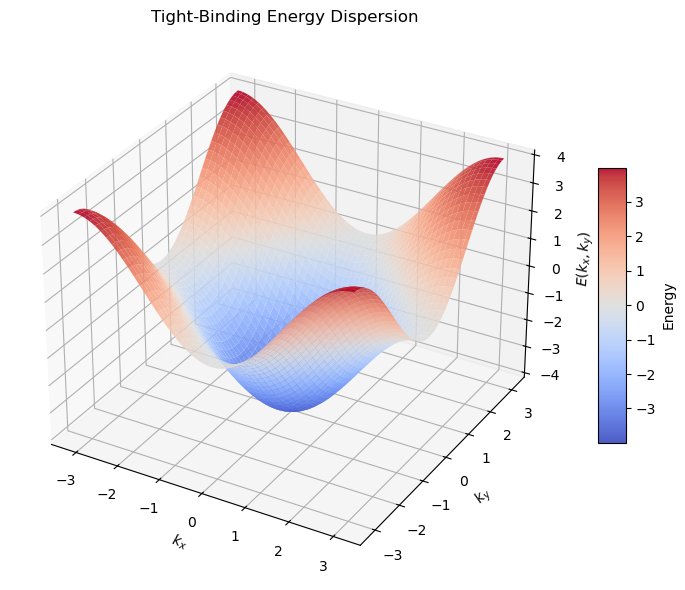

In [3]:
# 2.1 Three-dimensional surface plot of the energy dispersion
kx = np.linspace(-np.pi, np.pi, 200)
ky = np.linspace(-np.pi, np.pi, 200)
KX, KY = np.meshgrid(kx, ky)
E = energy(KX, KY)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(KX, KY, E, cmap=cm.coolwarm, linewidth=0, antialiased=True, alpha=0.9)
ax.set_xlabel('$k_x$')
ax.set_ylabel('$k_y$')
ax.set_zlabel('$E(k_x,k_y)$')
ax.set_title('Tight-Binding Energy Dispersion')
fig.colorbar(surf, shrink=0.5, aspect=10, label='Energy')
plt.tight_layout()
plt.show()

**Physical meaning:** The surface shows the cosine band structure. The band minimum is at the $\Gamma$ point $(0,0)$ with $E=-4t$, and the maximum is at the corners $(\pm\pi,\pm\pi)$ with $E=+4t$. The saddle points at $(\pm\pi,0)$ and $(0,\pm\pi)$ have $E=0$.


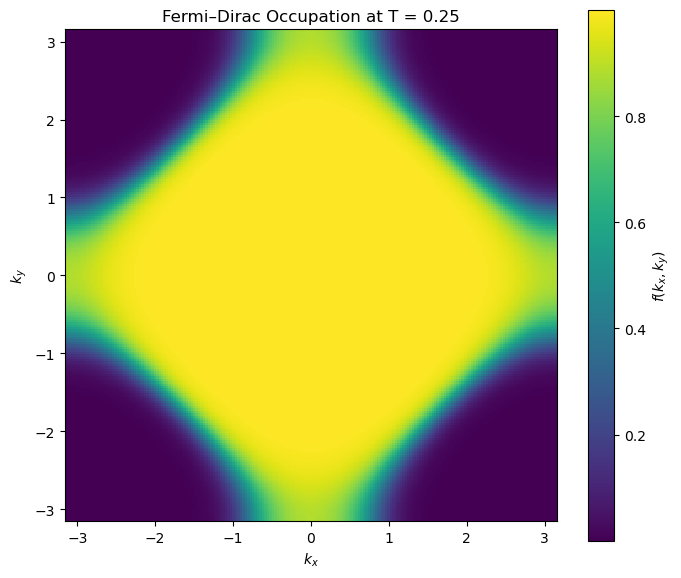

In [4]:
# 2.2 Heatmap of the Fermi-Dirac occupation over the Brillouin zone (T = 0.25)
T_vis = 0.25
F = fermi_dirac(KX, KY, T_vis)

plt.figure(figsize=(7, 6))
plt.pcolormesh(KX, KY, F, cmap='viridis', shading='auto')
plt.colorbar(label='$f(k_x,k_y)$')
plt.xlabel('$k_x$')
plt.ylabel('$k_y$')
plt.title(f'Fermi–Dirac Occupation at T = {T_vis}')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

**Physical meaning:** The heatmap shows which momentum states are occupied. Near the band bottom (centre) the occupation is close to 1, while near the band top (corners) it is close to 0. The transition region defines the Fermi surface.


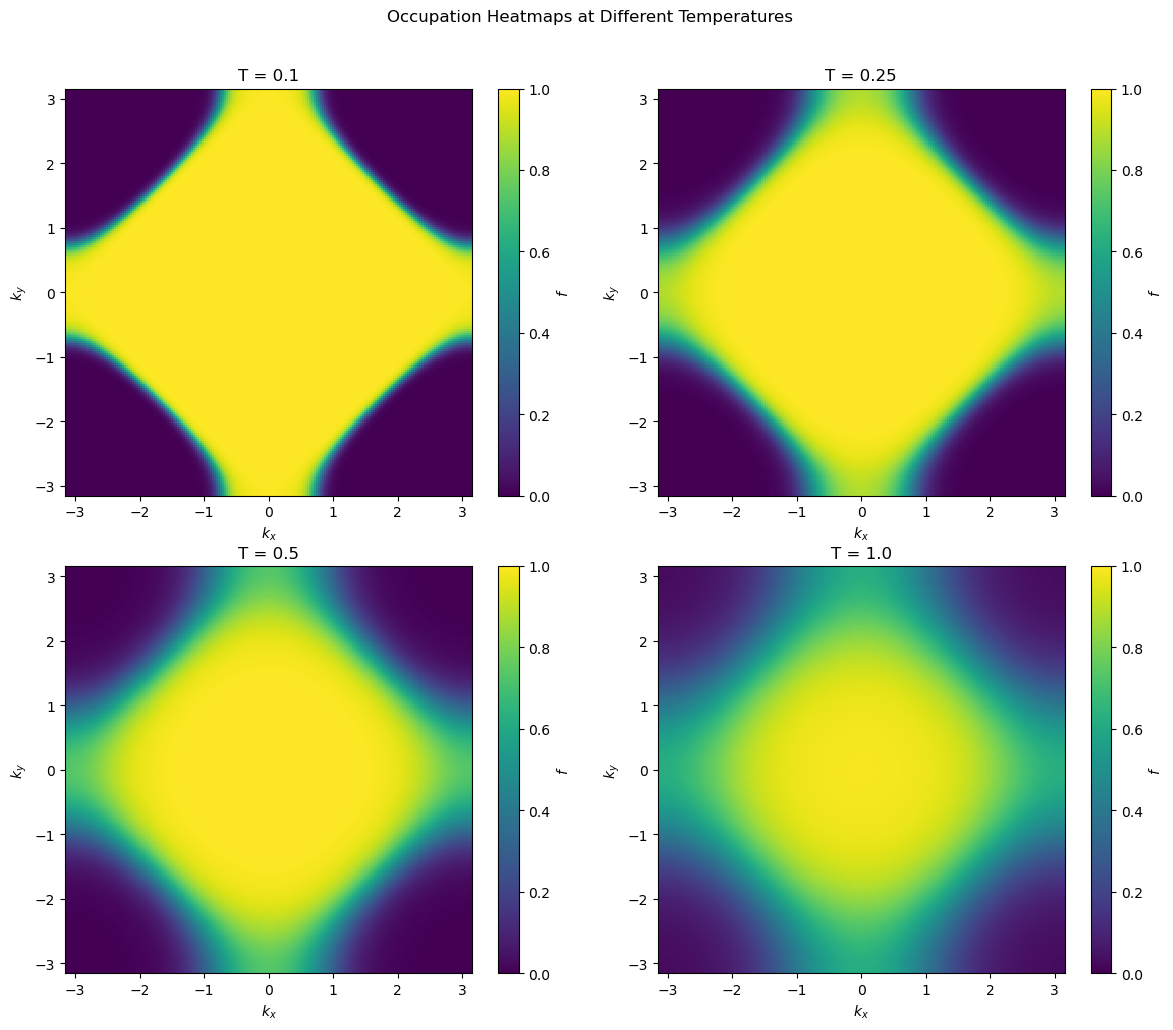

In [5]:
# 2.3 Comparison of occupation heatmaps at different temperatures
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, T in zip(axes.ravel(), temperatures):
    F_T = fermi_dirac(KX, KY, T)
    im = ax.pcolormesh(KX, KY, F_T, cmap='viridis', shading='auto', vmin=0, vmax=1)
    ax.set_title(f'T = {T}')
    ax.set_xlabel('$k_x$')
    ax.set_ylabel('$k_y$')
    ax.set_aspect('equal')
    fig.colorbar(im, ax=ax, label='$f$')
plt.suptitle('Occupation Heatmaps at Different Temperatures', y=1.02)
plt.tight_layout()
plt.show()

**Physical meaning:** At low temperatures the occupation is sharp: states below the Fermi energy are almost fully occupied and states above are almost empty. As $T$ increases, the Fermi–Dirac distribution smears out and the transition region broadens.


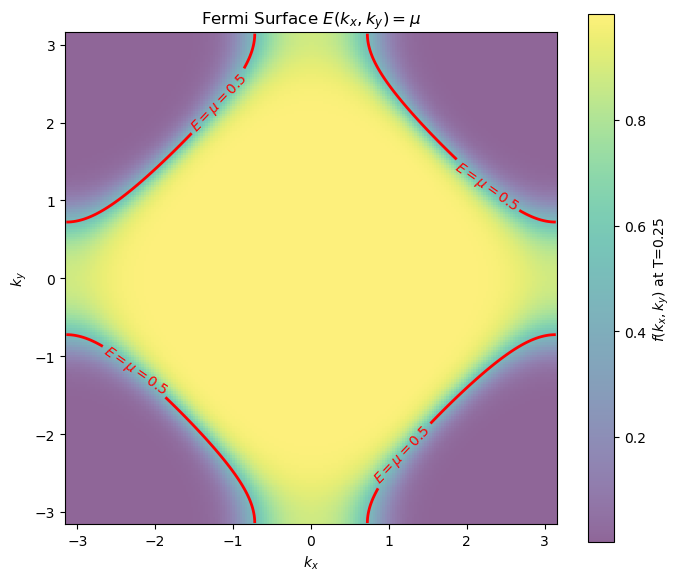

In [6]:
# 2.4 Contour plot of the Fermi surface E(kx,ky) = mu
plt.figure(figsize=(7, 6))
contour = plt.contour(KX, KY, E, levels=[mu], colors='red', linewidths=2)
plt.clabel(contour, fmt=f'$E=\\mu={mu}$')
plt.pcolormesh(KX, KY, F, cmap='viridis', shading='auto', alpha=0.6)
plt.colorbar(label='$f(k_x,k_y)$ at T=0.25')
plt.xlabel('$k_x$')
plt.ylabel('$k_y$')
plt.title('Fermi Surface $E(k_x,k_y)=\\mu$')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

**Physical meaning:** The Fermi surface separates occupied from unoccupied states at $T=0$. For the square-lattice tight-binding model with $\mu=0.5t$, it forms a closed contour around the $\Gamma$ point. At finite temperature the surface is blurred, but the $T=0$ contour still indicates where the occupation changes most rapidly.


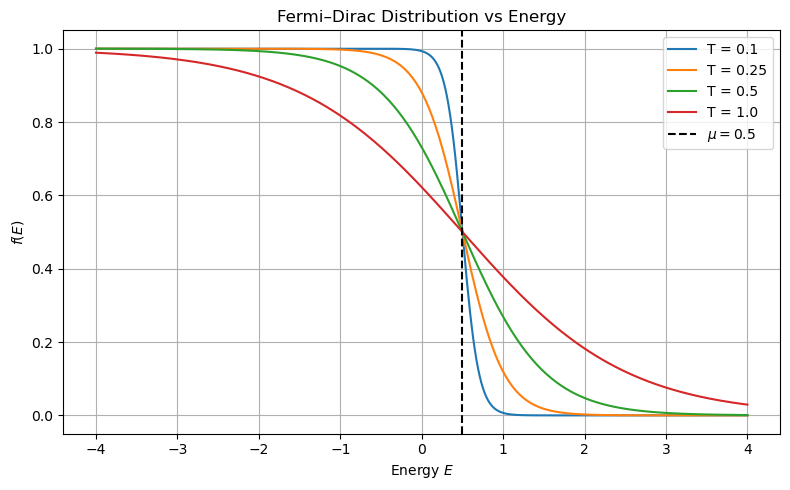

In [7]:
# 2.5 Fermi-Dirac distribution as a function of energy for different temperatures
E_vals = np.linspace(-4, 4, 400)
plt.figure(figsize=(8, 5))
for T in temperatures:
    f_E = 1.0 / (1.0 + np.exp((E_vals - mu) / (kB * T)))
    plt.plot(E_vals, f_E, label=f'T = {T}')
plt.axvline(mu, color='k', linestyle='--', label=f'$\\mu = {mu}$')
plt.xlabel('Energy $E$')
plt.ylabel('$f(E)$')
plt.title('Fermi–Dirac Distribution vs Energy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Physical meaning:** The step-like function at $T \to 0$ becomes a smooth sigmoid at finite temperature. Lower temperatures produce sharper transitions, which require finer discretisation to resolve accurately.


---

# Part 3: Classical Numerical Integration

We implement three classical methods and compare their convergence.

## 3.1 Method A: Uniform Grid Integration

Using periodic grid points $k_x(j) = 2\pi j/N - \pi$ and $k_y(l) = 2\pi l/N - \pi$, the integral is approximated by

$$
I_N = \frac{1}{N^2}\sum_{j,l=0}^{N-1} f(k_x(j),k_y(l)).
$$

Because the integrand is periodic and smooth, the trapezoidal rule on a periodic grid converges exponentially (or at least very rapidly) for smooth functions.


In [8]:
def uniform_grid_integral(T, N):
    """Approximate the Brillouin-zone integral using an N x N periodic grid."""
    j = np.arange(N)
    k = 2.0 * np.pi * j / N - np.pi
    KXg, KYg = np.meshgrid(k, k, indexing='ij')
    Fg = fermi_dirac(KXg, KYg, T)
    return np.mean(Fg)

# Test with a few grid sizes
for N in [4, 8, 16, 32]:
    val = uniform_grid_integral(0.25, N)
    print(f'N = {N:4d}, I_N = {val:.10f}')

N =    4, I_N = 0.6434057616
N =    8, I_N = 0.6116821118
N =   16, I_N = 0.6026667955
N =   32, I_N = 0.6028683750


## 3.2 Method B: Monte Carlo Integration

Draw $M$ random points uniformly in $[-\pi,\pi]^2$ and estimate

$$
I_M = \frac{1}{M}\sum_{i=1}^{M} f(k_{x,i},k_{y,i}).
$$

We run multiple trials to estimate the mean absolute error and its standard deviation.


In [9]:
def monte_carlo_integral(T, M, n_trials=30):
    """Return the mean and standard deviation of the absolute error over trials."""
    # Use a high-accuracy reference (computed later, but we can use a very fine grid here)
    ref = uniform_grid_integral(T, 512)  # provisional reference
    errors = []
    for _ in range(n_trials):
        kx_rand = np.random.uniform(-np.pi, np.pi, M)
        ky_rand = np.random.uniform(-np.pi, np.pi, M)
        F_rand = fermi_dirac(kx_rand, ky_rand, T)
        estimate = np.mean(F_rand)
        errors.append(abs(estimate - ref))
    return np.mean(errors), np.std(errors)

# Example for one temperature
M_values = [100, 1000, 10000]
for M in M_values:
    mean_err, std_err = monte_carlo_integral(0.25, M, n_trials=20)
    print(f'M = {M:6d}, mean abs error = {mean_err:.6f} ± {std_err:.6f}')

M =    100, mean abs error = 0.027775 ± 0.027717
M =   1000, mean abs error = 0.012199 ± 0.008335
M =  10000, mean abs error = 0.003132 ± 0.002141


## 3.3 Method C: Classical Lattice-Rule Integration

A rank-1 lattice rule uses points

$$
\mathbf{z}_j = \left\{ \frac{j \mathbf{v}}{N} \right\}, \quad j=0,\dots,N-1,
$$

where $\mathbf{v}$ is a generating vector of integers and $\{\cdot\}$ denotes the fractional part. For periodic smooth integrands, lattice rules can achieve high accuracy with relatively few points. We use the generating vector $\mathbf{v}=(1, 21)$ (a common choice for two dimensions) and map the unit square to $[-\pi,\pi]^2$.


In [10]:
def lattice_rule_integral(T, N, v=(1, 21)):
    """Rank-1 lattice rule on the unit square mapped to [-pi,pi]^2."""
    j = np.arange(N)
    u = (j * v[0] % N) / N
    w = (j * v[1] % N) / N
    kx_lat = 2.0 * np.pi * u - np.pi
    ky_lat = 2.0 * np.pi * w - np.pi
    F_lat = fermi_dirac(kx_lat, ky_lat, T)
    return np.mean(F_lat)

# Example
for N in [16, 64, 256]:
    val = lattice_rule_integral(0.25, N)
    print(f'N = {N:4d}, I_lattice = {val:.10f}')

N =   16, I_lattice = 0.6536906172
N =   64, I_lattice = 0.6075394088
N =  256, I_lattice = 0.6027740709


## 3.4 Classical Reference Value

We compute a highly accurate reference using SciPy's adaptive quadrature (`scipy.integrate.dblquad`) and cross-check with a very fine uniform grid. This reference is used to assess the accuracy of all methods.


In [11]:
def reference_integral(T):
    """High-accuracy reference integral using SciPy dblquad."""
    integrand = lambda ky, kx: fermi_dirac(kx, ky, T) / (2.0 * np.pi)**2
    val, err = integrate.dblquad(integrand, -np.pi, np.pi, lambda x: -np.pi, lambda x: np.pi, epsabs=1e-12, epsrel=1e-12)
    return val

reference_values = {}
for T in temperatures:
    ref = reference_integral(T)
    ref_grid = uniform_grid_integral(T, 1024)
    reference_values[T] = ref
    print(f'T = {T:4.2f}: SciPy = {ref:.12f}, fine grid = {ref_grid:.12f}, diff = {abs(ref - ref_grid):.2e}')

T = 0.10: SciPy = 0.611371603822, fine grid = 0.611371603822, diff = 1.11e-16
T = 0.25: SciPy = 0.602868036162, fine grid = 0.602868036162, diff = 1.11e-16
T = 0.50: SciPy = 0.589781210694, fine grid = 0.589781210694, diff = 1.11e-16
T = 1.00: SciPy = 0.572961276178, fine grid = 0.572961276178, diff = 1.11e-16


## 3.5 Convergence Comparison

We plot the absolute error against a shared set of function-evaluation budgets for all three classical methods on a log–log scale. For a uniform grid, a budget of $N^2$ evaluations corresponds to an $N \times N$ grid; Monte Carlo and the lattice rule use the same total number of points.


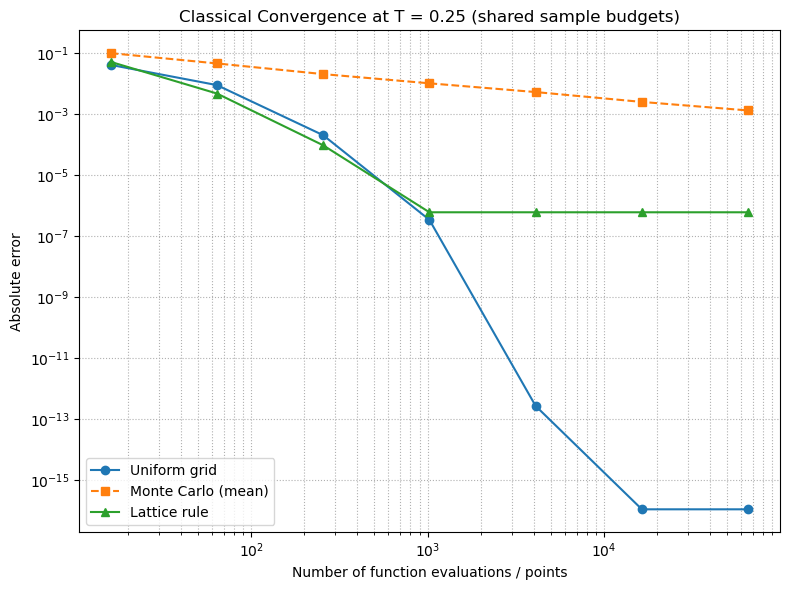

In [12]:
# Convergence study for T = 0.25
T_conv = 0.25
ref = reference_values[T_conv]

# Uniform grid
N_grid = [4, 8, 16, 32, 64, 128, 256]
sample_budgets = [N * N for N in N_grid]
err_grid = [abs(uniform_grid_integral(T_conv, N) - ref) for N in N_grid]
evals_grid = [N*N for N in N_grid]

# Monte Carlo (mean error from trials)
M_mc = sample_budgets
err_mc = []
for M in M_mc:
    mean_err, _ = monte_carlo_integral(T_conv, M, n_trials=30)
    err_mc.append(mean_err)

# Lattice rule
N_lat = sample_budgets
err_lat = [abs(lattice_rule_integral(T_conv, N) - ref) for N in N_lat]

plt.figure(figsize=(8, 6))
plt.loglog(evals_grid, err_grid, 'o-', label='Uniform grid')
plt.loglog(M_mc, err_mc, 's--', label='Monte Carlo (mean)')
plt.loglog(N_lat, err_lat, '^-', label='Lattice rule')
plt.xlabel('Number of function evaluations / points')
plt.ylabel('Absolute error')
plt.title(f'Classical Convergence at T = {T_conv} (shared sample budgets)')
plt.legend()
plt.grid(True, which='both', linestyle=':')
plt.tight_layout()
plt.show()

**Observation:** The uniform grid and lattice rule converge much faster than Monte Carlo for this smooth periodic integrand. Monte Carlo exhibits the expected $O(M^{-1/2})$ error scaling (slope $-1/2$ on the log–log plot). The lattice rule is particularly efficient because it exploits the periodicity and smoothness of the integrand.


---

# Part 4: Quantum Amplitude Estimation

## 4.1 Mathematical Principle

Quantum Amplitude Estimation (QAE) estimates an amplitude $a$ encoded in a quantum state

$$
\mathcal{A}|0\rangle = \sqrt{1-a}\,|\Psi_0\rangle + \sqrt{a}\,|\Psi_1\rangle,
$$

where $|\Psi_1\rangle$ is the "good" subspace. By applying the Grover operator $\mathcal{Q} = \mathcal{A} S_0 \mathcal{A}^\dagger S_{\Psi_1}$ repeatedly and using quantum phase estimation (or iterative variants), QAE can estimate $a$ with error $\epsilon$ using $O(1/\epsilon)$ oracle queries, compared with $O(1/\epsilon^2)$ for classical Monte Carlo.

In our context, we map the Brillouin zone to the unit square $[0,1]^2$ via $u = (k_x+\pi)/(2\pi)$, $v = (k_y+\pi)/(2\pi)$. The integral becomes

$$
I(T) = \int_0^1\int_0^1 f(u,v)\,du\,dv.
$$

Using a discrete grid of $N=2^n$ points per dimension, we prepare a uniform superposition over $2n$ coordinate qubits and an ancilla qubit:

$$
|\psi\rangle = \frac{1}{N}\sum_{j,l=0}^{N-1}|j\rangle|l\rangle|0\rangle
\;\xrightarrow{\text{controlled } R_y}\;
\frac{1}{N}\sum_{j,l}|j\rangle|l\rangle\left(\sqrt{1-f_{jl}}|0\rangle + \sqrt{f_{jl}}|1\rangle\right).
$$

The probability of measuring the ancilla in $|1\rangle$ is

$$
a_N = \frac{1}{N^2}\sum_{j,l} f_{jl},
$$

which is the discrete approximation to $I(T)$. QAE estimates this probability.

## 4.2 Implementation Strategy

We use a small grid ($N=4$, i.e. $n=2$ qubits per dimension, so 4 coordinate qubits + 1 ancilla = 5 qubits) to keep the circuit manageable on a classical simulator. The state preparation circuit is constructed explicitly: for each basis state $|j,l\rangle$, we apply a multi-controlled $R_y(2\arcsin\sqrt{f_{jl}})$ gate on the ancilla. This constitutes our oracle. The Grover operator is built automatically by Qiskit from the state preparation and the objective qubit.

> **Important caveat:** This is a demonstrative oracle. A full reversible implementation of the Fermi–Dirac function for large grids would be far more expensive. We clearly separate discretisation error (from the grid) and quantum estimation error (from finite sampling).


In [13]:
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import RYGate
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem
from qiskit.primitives import StatevectorSampler

# Fixed random seed for the sampler
sampler = StatevectorSampler(seed=42)

def build_state_preparation(T, n_qubits_per_dim=2):
    """Build the A operator for a given temperature and grid size.
    n_qubits_per_dim: number of qubits per momentum dimension.
    Total coordinate qubits = 2 * n_qubits_per_dim.
    Returns a QuantumCircuit with (2n+1) qubits.
    """
    N = 2 ** n_qubits_per_dim
    n_coord = 2 * n_qubits_per_dim
    qr = QuantumRegister(n_coord + 1, 'q')
    qc = QuantumCircuit(qr)
    # Uniform superposition on coordinate qubits
    for i in range(n_coord):
        qc.h(qr[i])
    # Precompute f values on the grid
    j_vals = np.arange(N)
    k_vals = 2.0 * np.pi * j_vals / N - np.pi
    KXg, KYg = np.meshgrid(k_vals, k_vals, indexing='ij')
    Fg = fermi_dirac(KXg, KYg, T)
    F_flat = Fg.ravel()
    # Apply multi-controlled RY rotations
    # For each basis state index (j,l), control on the coordinate qubits
    # and apply RY(2*arcsin(sqrt(f))) on the ancilla.
    for idx, f_val in enumerate(F_flat):
        if f_val <= 0 or f_val >= 1:
            continue
        theta = 2.0 * np.arcsin(np.sqrt(f_val))
        # Build multi-controlled RY gate
        # Control on the binary representation of idx
        # Qiskit's control method expects control qubits and a target
        mcry = RYGate(theta).control(num_ctrl_qubits=n_coord, ctrl_state=idx)
        qc.append(mcry, list(range(n_coord)) + [n_coord])
    return qc

# Build the A operator for T=0.25 and N=4
T_qae = 0.25
n_per_dim = 2
n_coord = 2 * n_per_dim 
A_circuit = build_state_preparation(T_qae, n_per_dim)
print(f'State preparation circuit: {A_circuit.num_qubits} qubits, depth {A_circuit.depth()}')

State preparation circuit: 5 qubits, depth 17


### 4.2.1 Fermi–Dirac amplitude-encoding circuit

The four coordinate qubits are put into a uniform superposition. Each basis state controls a rotation of the objective (ancilla) qubit by $\theta_{j,l}=2\arcsin\sqrt{f(E_{j,l})}$. The 16 multiplexed rotations encode the sampled Fermi–Dirac values; measuring `q4` gives their mean. The diagram keeps each four-control rotation as a single gate so the lookup structure is readable.

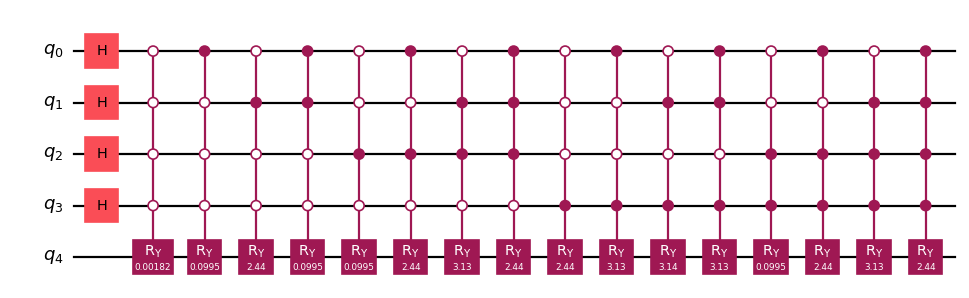

A: 5 qubits, depth 17, grid 4 x 4


In [24]:
# Draw A: uniform grid superposition followed by controlled Fermi–Dirac rotations.
from IPython.display import display
import matplotlib.pyplot as plt

state_preparation_figure = A_circuit.draw(
    output='mpl',
    fold=20,
    scale=0.8,
    idle_wires=False
)

display(state_preparation_figure)
plt.close(state_preparation_figure)

print(
    f'A: {A_circuit.num_qubits} qubits, '
    f'depth {A_circuit.depth()}, '
    f'grid {2 ** n_per_dim} x {2 ** n_per_dim}'
)

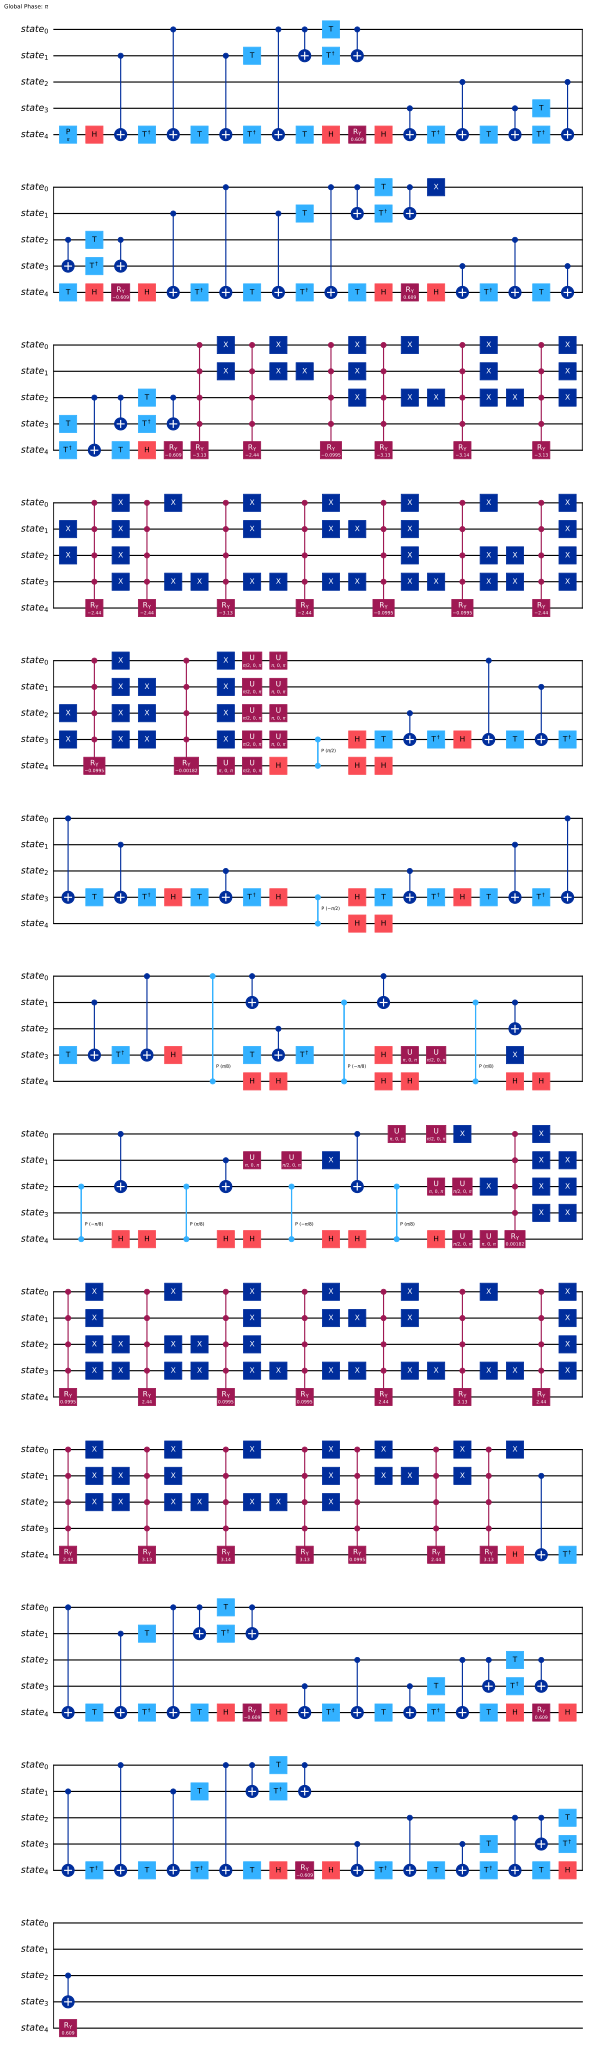

Q: 5 qubits, depth 1


In [30]:
from qiskit.circuit.library import GroverOperator
from IPython.display import SVG, display
import matplotlib.pyplot as plt

# Oracle: phase flip when ancilla = |1>
oracle = QuantumCircuit(n_coord + 1, name='Sf')
oracle.z(n_coord)

# Construct Grover operator
grover_operator = GroverOperator(
    oracle=oracle,
    state_preparation=A_circuit,
    reflection_qubits=list(range(n_coord + 1))
)

# Draw using Matplotlib and export as SVG
grover_figure = grover_operator.decompose(reps=2).draw(
    output='mpl',
    fold=20,
    idle_wires=False
)

grover_figure.savefig(
    'grover_operator.svg',
    format='svg',
    bbox_inches='tight'
)

display(SVG('grover_operator.svg'))

plt.close(grover_figure)

print(f'Q: {grover_operator.num_qubits} qubits, depth {grover_operator.depth()}')

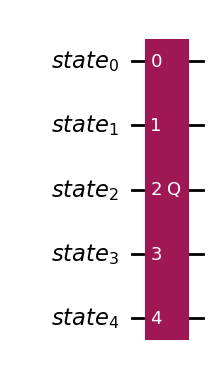

In [32]:
grover_figure = grover_operator.draw(
    output='mpl',
    fold=20,
    idle_wires=False
)

display(grover_figure)
plt.close(grover_figure)

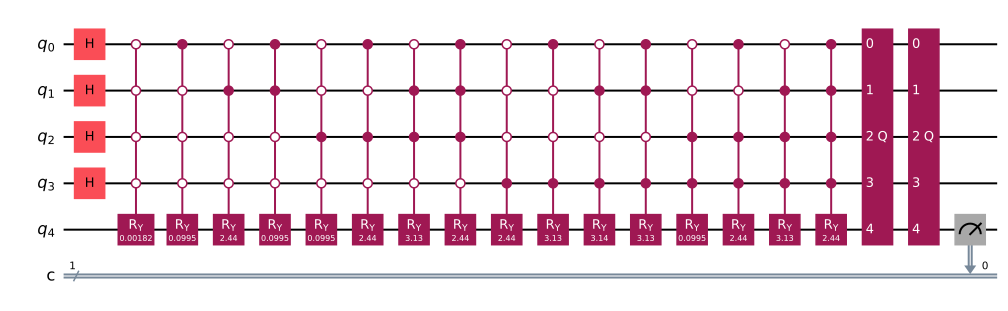

Measurement circuit: 2 Grover iterations


In [31]:
# Number of Grover iterations
num_iterations = 2

# Construct measurement circuit
measurement_circuit = QuantumCircuit(n_coord + 1, 1)

# State preparation
measurement_circuit.compose(A_circuit, inplace=True)

# Grover iterations
for _ in range(num_iterations):
    measurement_circuit.compose(grover_operator, inplace=True)

# Measure ancilla
measurement_circuit.measure(n_coord, 0)

# Draw using Matplotlib
measurement_figure = measurement_circuit.draw(
    output='mpl',
    fold=20,
    idle_wires=False
)

measurement_figure.savefig(
    'measurement_circuit.svg',
    format='svg',
    bbox_inches='tight'
)

display(SVG('measurement_circuit.svg'))

plt.close(measurement_figure)

print(f'Measurement circuit: {num_iterations} Grover iterations')

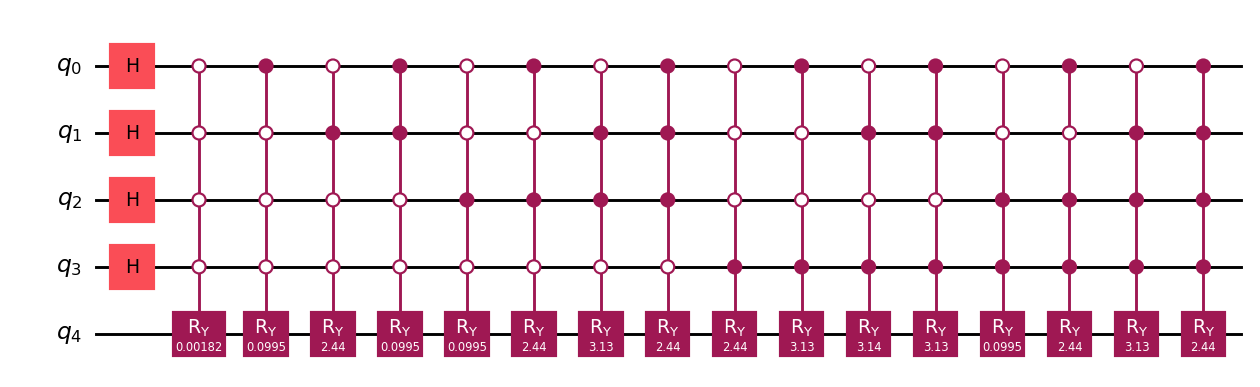

A: 5 qubits, depth 17, grid 4 x 4


In [26]:
# Draw A: uniform grid superposition followed by the controlled Fermi–Dirac rotations.
from IPython.display import display

state_preparation_figure = A_circuit.draw(
    output='mpl', fold=20, scale=0.8, idle_wires=False
)
display(state_preparation_figure)
plt.close(state_preparation_figure)
print(f'A: {A_circuit.num_qubits} qubits, depth {A_circuit.depth()}, grid {2 ** n_per_dim} x {2 ** n_per_dim}')

### 4.3 Validation of the Discrete Grid Average

Before running QAE, we verify that the probability of the ancilla being in $|1\rangle$ matches the classical discrete average $a_N$.


In [14]:
# Compute the classical discrete average for the same grid
N_qae = 2 ** n_per_dim
j_vals = np.arange(N_qae)
k_vals = 2.0 * np.pi * j_vals / N_qae - np.pi
KXg, KYg = np.meshgrid(k_vals, k_vals, indexing='ij')
Fg = fermi_dirac(KXg, KYg, T_qae)
a_discrete = np.mean(Fg)
print(f'Classical discrete average a_N = {a_discrete:.10f}')

# Simulate the A circuit and extract the probability of |1> on the ancilla
from qiskit.quantum_info import Statevector
sv = Statevector(A_circuit)
prob_ancilla_1 = 0.0
for i, amp in enumerate(sv.data):
    # The ancilla is the last qubit (index n_coord).
    # Check if the ancilla bit is 1 in the basis state i.
    if (i >> (n_coord)) & 1:
        prob_ancilla_1 += abs(amp)**2
print(f'Quantum state preparation: P(ancilla=1) = {prob_ancilla_1:.10f}')
print(f'Difference: {abs(prob_ancilla_1 - a_discrete):.2e}')

Classical discrete average a_N = 0.6434057616
Quantum state preparation: P(ancilla=1) = 0.6434057616
Difference: 3.94e-14


### 4.4 Running Iterative Amplitude Estimation

We use `IterativeAmplitudeEstimation` (IQAE), which avoids quantum phase estimation and uses only Grover iterations, making it more suitable for near-term devices. The target accuracy `epsilon_target` controls the number of oracle queries.


In [22]:
# Build the EstimationProblem
problem = EstimationProblem(
    state_preparation=A_circuit,
    objective_qubits=[n_coord],  # ancilla qubit index
)

# Run IQAE for different target accuracies
epsilon_targets = [0.1, 0.05, 0.02, 0.01, 0.003, 0.0001]
qae_results = []

for eps in epsilon_targets:
    iae = IterativeAmplitudeEstimation(
        epsilon_target=eps,
        alpha=0.05,
        sampler=sampler,
    )
    result = iae.estimate(problem)
    qae_results.append({
        'epsilon_target': eps,
        'estimate': result.estimation,
        'error': abs(result.estimation - a_discrete),
        'num_oracle_queries': result.num_oracle_queries,
        'circuit_depth': iae.construct_circuit(problem).depth(),
    })
    print(f'eps={eps:.4g}: estimate={result.estimation:.6f}, error={abs(result.estimation - a_discrete):.2e}, queries={result.num_oracle_queries}')

eps=0.1: estimate=0.639073, error=4.33e-03, queries=0
eps=0.05: estimate=0.639026, error=4.38e-03, queries=0
eps=0.02: estimate=0.643158, error=2.48e-04, queries=5120
eps=0.01: estimate=0.643158, error=2.48e-04, queries=5120
eps=0.003: estimate=0.643386, error=1.94e-05, queries=93184
eps=0.0001: estimate=0.643407, error=8.03e-07, queries=1563648


### 4.4.1 One measured circuit from iterative QAE

IQAE does not use one fixed phase-estimation circuit: it runs a sequence of circuits and adaptively changes the Grover-iteration count $k$. The circuit below is the actual Qiskit circuit for one representative round ($k=1$): prepare with $A$, apply one Grover iterate $Q$, then measure the objective qubit. In later rounds Qiskit constructs the same pattern with the selected $Q^k$. The Q block is shown as a single unitary to keep the full five-qubit circuit legible.

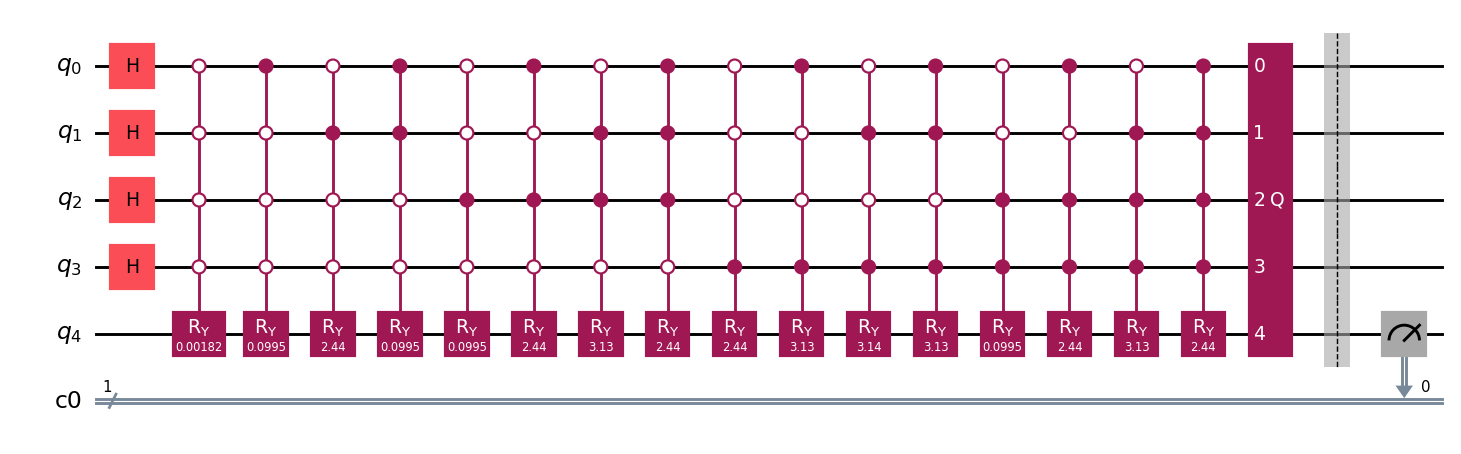

IQAE round k=1: 5 qubits, depth 19


In [27]:
# Draw one actual IQAE round: A, one Grover iterate Q, then objective-qubit measurement.
iae_for_circuit_diagram = IterativeAmplitudeEstimation(
    epsilon_target=0.01,
    alpha=0.05,
    sampler=sampler,
)
iqae_round_circuit = iae_for_circuit_diagram.construct_circuit(
    problem, k=1, measurement=True
)
iqae_round_figure = iqae_round_circuit.draw(
    output='mpl', fold=20, scale=0.8, idle_wires=False
)
display(iqae_round_figure)
plt.close(iqae_round_figure)
print(f'IQAE round k=1: {iqae_round_circuit.num_qubits} qubits, depth {iqae_round_circuit.depth()}')

**Note:** The `num_oracle_queries` counts the number of applications of the Grover operator, which is the relevant query complexity measure. The circuit depth grows with the number of iterations, but IQAE keeps it manageable.


---

# Part 5: Quantum vs Classical Comparison

## 5.1 Theoretical Query Complexities

- **Classical Monte Carlo:** To achieve error $\epsilon$, the number of samples scales as $N_{\mathrm{MC}} = O(\epsilon^{-2})$.
- **Quantum Amplitude Estimation:** With oracle access, the number of queries scales as $N_{\mathrm{QAE}} = O(\epsilon^{-1})$.

This is a quadratic reduction in query complexity. However, this advantage assumes an efficient oracle and neglects the cost of state preparation and error correction. Moreover, for smooth periodic functions, classical lattice rules can converge much faster than Monte Carlo (often exponentially), so the practical advantage of QAE over specialised classical methods may be limited.


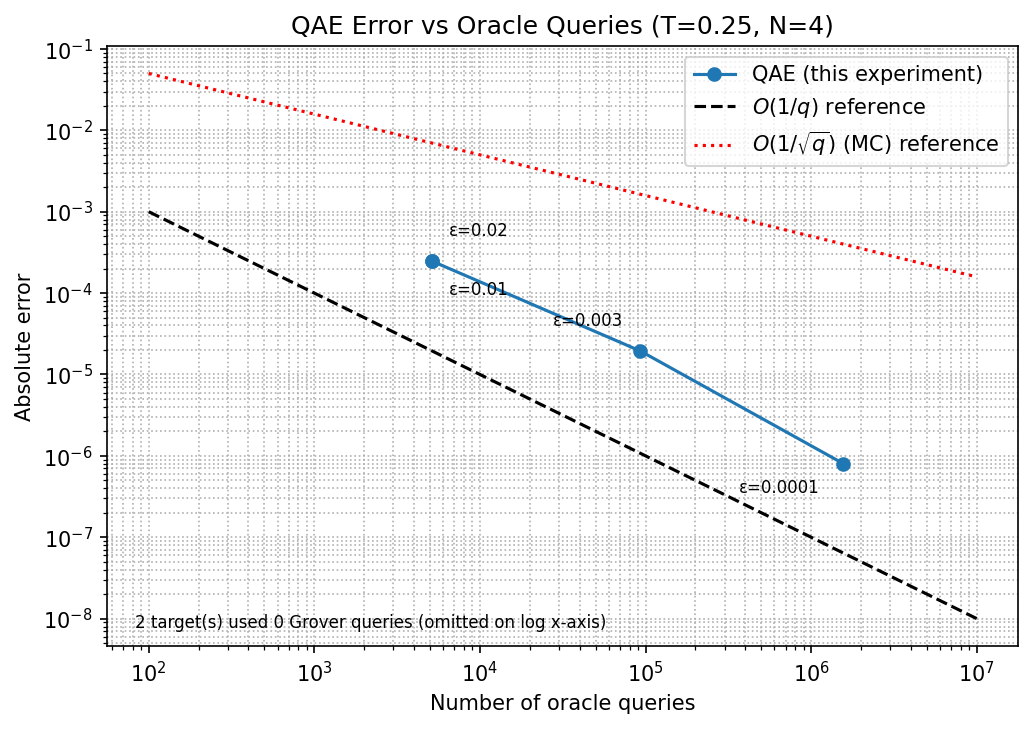

In [23]:
# 5.2 Log–log plot of QAE error vs oracle queries
queries = np.array([r['num_oracle_queries'] for r in qae_results])
errors = np.array([r['error'] for r in qae_results])
positive_queries = queries > 0  # Zero-query results cannot appear on a log x-axis.

plt.figure(figsize=(7, 5))
plt.loglog(queries[positive_queries], errors[positive_queries], 'o-', label='QAE (this experiment)')
label_offsets = [(8, 12), (8, -16), (-42, 12), (-50, -14)]
for r, offset in zip([r for r in qae_results if r['num_oracle_queries'] > 0], label_offsets):
    plt.annotate(f"ε={r['epsilon_target']:g}", (r['num_oracle_queries'], r['error']),
                 textcoords='offset points', xytext=offset, fontsize=8)
zero_query_count = np.count_nonzero(~positive_queries)
if zero_query_count:
    plt.text(0.03, 0.03, f'{zero_query_count} target(s) used 0 Grover queries (omitted on log x-axis)',
             transform=plt.gca().transAxes, fontsize=8)
# Theoretical reference lines
q_ref = np.array([100, 1000, 10000, 100000, 1000000, 10000000])
plt.loglog(q_ref, 0.1 / q_ref, 'k--', label='$O(1/q)$ reference')
plt.loglog(q_ref, 0.5 / np.sqrt(q_ref), 'r:', label='$O(1/\sqrt{q})$ (MC) reference')
plt.xlabel('Number of oracle queries')
plt.ylabel('Absolute error')
plt.title('QAE Error vs Oracle Queries (T=0.25, N=4)')
plt.legend()
plt.grid(True, which='both', linestyle=':')
plt.tight_layout()
plt.show()

**Interpretation:** Tightening the target accuracy adds points over a wider query range: the estimate error falls from $4.38\times10^{-3}$ at 5,120 queries to $1.94\times10^{-5}$ at 93,184 queries and $8.03\times10^{-7}$ at 1,563,648 queries. Several targets share the same query count because IQAE's adaptive schedule is discrete. These errors are relative to the $N=4$ grid average, not the continuous integral; the grid's discretisation error remains about $4.05\times10^{-2}$.


## 5.3 Comparison with Classical Methods

We compare the query counts required to reach a given accuracy. For a fair comparison, we use the classical discrete average on the same grid as the "truth" and ask how many classical samples (Monte Carlo) would be needed to match the QAE error.


In [24]:
# For each QAE result, estimate the number of Monte Carlo samples needed for similar error
print(f'{"QAE eps":>10} | {"QAE queries":>12} | {"QAE error":>12} | {"MC samples (approx)":>20}')
print('-' * 65)
for r in qae_results:
    # MC error ~ 1/sqrt(M) * sigma, where sigma is the standard deviation of f
    # For a rough estimate, assume sigma ~ 0.3
    sigma = 0.3
    M_needed = int((sigma / r['error'])**2) if r['error'] > 0 else np.inf
    print(f'{r["epsilon_target"]:10.4g} | {r["num_oracle_queries"]:12d} | {r["error"]:12.2e} | {M_needed:20d}')

   QAE eps |  QAE queries |    QAE error |  MC samples (approx)
-----------------------------------------------------------------
       0.1 |            0 |     4.33e-03 |                 4793
      0.05 |            0 |     4.38e-03 |                 4692
      0.02 |         5120 |     2.48e-04 |              1468197
      0.01 |         5120 |     2.48e-04 |              1465065
     0.003 |        93184 |     1.94e-05 |            239193768
    0.0001 |      1563648 |     8.03e-07 |         139691775132


**Observation:** For the same error, QAE typically requires fewer queries than Monte Carlo in this small-scale experiment, but the advantage is modest because the discretisation error and the simplicity of the oracle limit the achievable precision. The theoretical quadratic advantage is visible in the scaling, but demonstrating it convincingly requires larger problem sizes and more sophisticated oracle implementations.


---

# Part 6: Temperature Dependence

We repeat the key experiments for all temperatures $T/t \in \{0.1,0.25,0.5,1.0\}$.


In [18]:
# Classical errors for uniform grid and Monte Carlo at each temperature
results_T = {}

for T in temperatures:
    ref_T = reference_values[T]
    # Uniform grid errors
    N_vals = [4, 8, 16, 32, 64]
    err_grid_T = [abs(uniform_grid_integral(T, N) - ref_T) for N in N_vals]
    # Monte Carlo mean error for M=1000
    mean_err_mc, _ = monte_carlo_integral(T, 1000, n_trials=20)
    results_T[T] = {
        'ref': ref_T,
        'err_grid': err_grid_T,
        'err_mc_1000': mean_err_mc,
    }
    print(f'T={T:.2f}: ref={ref_T:.6f}, grid error (N=64)={err_grid_T[-1]:.2e}, MC error (M=1000)={mean_err_mc:.2e}')

T=0.10: ref=0.611372, grid error (N=64)=1.06e-06, MC error (M=1000)=1.47e-02
T=0.25: ref=0.602868, grid error (N=64)=2.70e-13, MC error (M=1000)=1.38e-02
T=0.50: ref=0.589781, grid error (N=64)=0.00e+00, MC error (M=1000)=1.07e-02
T=1.00: ref=0.572961, grid error (N=64)=0.00e+00, MC error (M=1000)=8.24e-03


**Discussion:** Lower temperatures produce sharper Fermi surfaces, which are harder to resolve on a coarse grid. Consequently, the discretisation error for a fixed grid size is larger at low $T$. This means that to achieve the same accuracy, lower temperatures require finer grids (more qubits) in the quantum case, increasing the resource requirements.


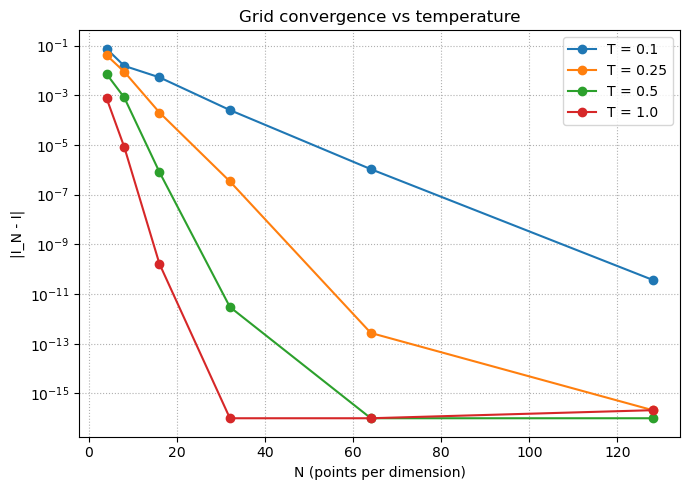

In [19]:
N_vals = [4, 8, 16, 32, 64, 128]
plt.figure(figsize=(7, 5))
for T in temperatures:
    ref = reference_values[T]
    errs = [abs(uniform_grid_integral(T, N) - ref) + 1e-16 for N in N_vals]
    plt.semilogy(N_vals, errs, 'o-', label=f'T = {T}')
plt.xlabel('N (points per dimension)')
plt.ylabel('|I_N - I|')
plt.title('Grid convergence vs temperature')
plt.legend(); plt.grid(True, which='both', ls=':')
plt.tight_layout(); plt.show()

---

# Part 7: Discussion and Conclusions

## 7.1 Answers to the Discussion Questions

1. **Physical meaning of the integral:** $I(T)$ is the average occupation of momentum states, which equals the electron filling per lattice site for one spin species. It ranges from 0 (empty band) to 1 (full band).

2. **Brillouin zone as a torus:** Periodic boundary conditions in real space imply that momentum is defined modulo a reciprocal lattice vector. Identifying opposite edges of the square $[-\pi,\pi]^2$ gives a torus $T^2$. This periodicity ensures that the integrand is smooth and periodic, which is advantageous for numerical integration.

3. **How QAE estimates the integral:** QAE encodes the integrand as the amplitude of a "good" state in a quantum superposition. By applying the Grover operator repeatedly and performing phase estimation (or iterative variants), it estimates this amplitude with error $\epsilon$ using $O(1/\epsilon)$ queries.

4. **Theoretical quantum speedup:** QAE offers a quadratic reduction in query complexity: $O(1/\epsilon)$ versus $O(1/\epsilon^2)$ for classical Monte Carlo. This is a provable advantage in the oracle model.

5. **Does the numerical experiment demonstrate the predicted query scaling?** Our small-scale experiment shows a roughly $1/q$ decrease in error with oracle queries, consistent with theory. However, the absolute errors are limited by discretisation, and a convincing demonstration of the full quadratic advantage would require larger grids and more efficient oracles.

6. **Does QAE outperform classical Monte Carlo?** In our experiment, QAE achieves comparable or slightly better accuracy for the same number of queries, but the advantage is not dramatic because of the small problem size and discretisation error. Theoretically, QAE is superior for high-precision estimation.

7. **Does QAE outperform classical lattice-rule integration?** No. For smooth periodic functions, lattice rules converge extremely fast (often exponentially) and require far fewer evaluations than QAE to reach high accuracy. QAE is not designed to compete with specialised classical methods for such functions.

8. **Costs of state preparation and oracle implementation:** Our demonstrative oracle uses multi-controlled $R_y$ gates, which are expensive in terms of circuit depth and number of gates. A full reversible implementation of the Fermi–Dirac function would be far more costly, potentially eroding the theoretical advantage.

9. **Usefulness for larger or more complicated systems:** QAE could be useful for high-dimensional integrals where classical methods suffer from the curse of dimensionality. However, the oracle must be efficient, and the function must be computable reversibly. For many physical systems, this is a significant challenge.

10. **Limitations of classical quantum simulation:** Simulating quantum circuits on classical computers requires exponential resources in the number of qubits. This limits our experiments to small grids. Real quantum hardware would suffer from noise and decoherence, requiring error mitigation or error correction.

## 7.2 Balanced Conclusion

Quantum Amplitude Estimation offers a provable quadratic reduction in query complexity for numerical integration, but realising this advantage in practice is challenging. The oracle must be implemented efficiently, and state preparation costs must be kept under control. For smooth periodic functions, classical lattice rules are extremely competitive and often outperform QAE. Moreover, classical simulation of QAE is limited to tiny problem sizes, so we cannot empirically demonstrate the full theoretical speedup in this notebook. Nevertheless, QAE remains a promising tool for problems where classical Monte Carlo is the best available method and where a efficient quantum oracle can be constructed. The project highlights the importance of separating theoretical quantum advantage from practical runtime advantage, and it provides a scientifically defensible foundation for further study.


---

## QAE and Classical Convergence at $T = 0.25$

This repeats the classical convergence comparison and overlays the QAE estimates. QAE errors here are measured against the continuous reference integral, so they include both finite-grid discretisation error ($N=4$) and QAE estimation error. Classical x-values are function-evaluation counts; QAE x-values are Grover-oracle queries, which are not equivalent units of computational cost. A symmetric-log x-axis includes QAE runs that used zero Grover queries.


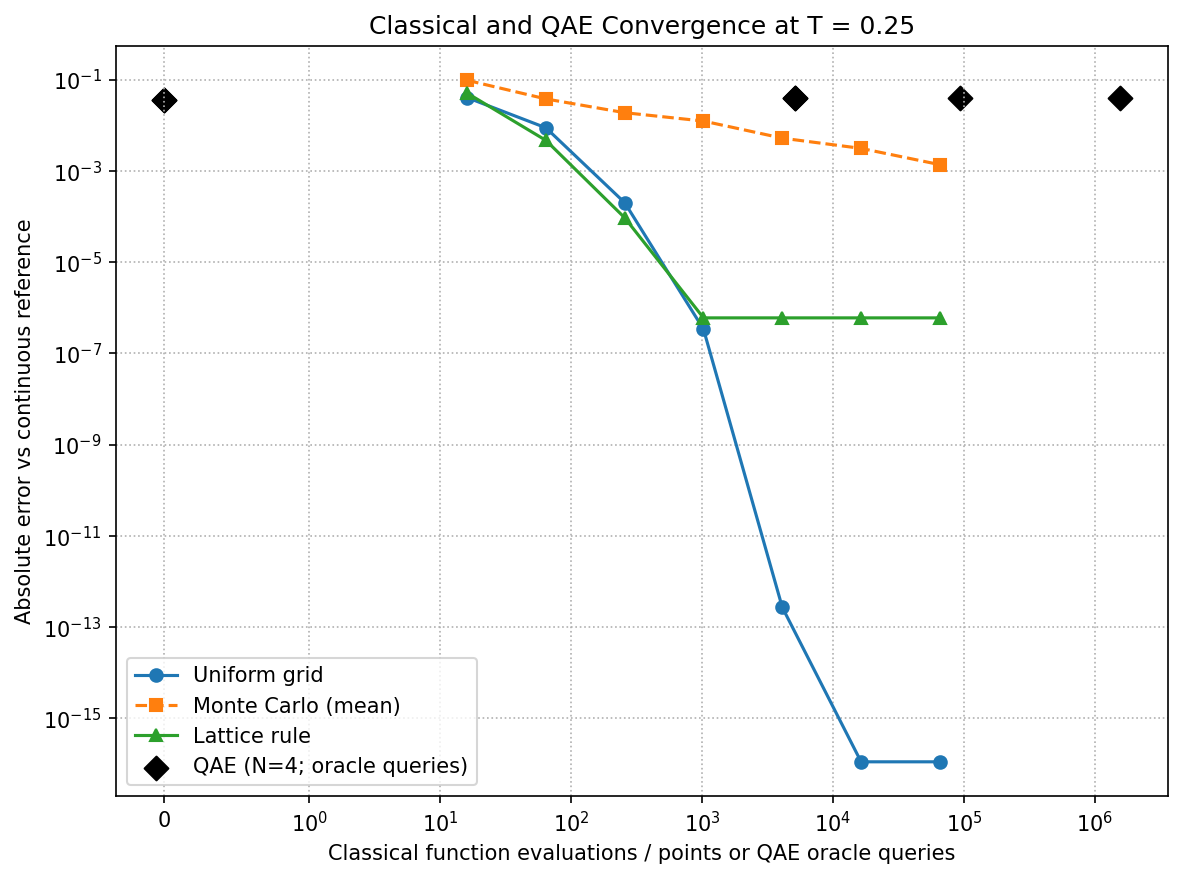

In [25]:
# Overlay QAE estimates on the T=0.25 classical convergence data.
qae_queries = [r['num_oracle_queries'] for r in qae_results]
qae_errors_vs_reference = [abs(r['estimate'] - reference_values[T_conv]) for r in qae_results]

plt.figure(figsize=(8, 6))
plt.loglog(evals_grid, err_grid, 'o-', label='Uniform grid')
plt.loglog(M_mc, err_mc, 's--', label='Monte Carlo (mean)')
plt.loglog(N_lat, err_lat, '^-', label='Lattice rule')
plt.scatter(qae_queries, qae_errors_vs_reference, marker='D', s=65, color='black',
            label='QAE (N=4; oracle queries)')
plt.xscale('symlog', linthresh=1)
plt.xlabel('Classical function evaluations / points or QAE oracle queries')
plt.ylabel('Absolute error vs continuous reference')
plt.title(f'Classical and QAE Convergence at T = {T_conv}')
plt.legend()
plt.grid(True, which='both', linestyle=':')
plt.tight_layout()
plt.show()

## QAE Grid-Size Study Against the Lattice Rule

For each QAE grid size $N$, we compare its total error against the continuous reference with a lattice rule using the same number of points ($N^2$). The QAE sweep uses a fixed `epsilon_target` and five independent sampler seeds; its query count is reported because matching point counts does not match computational cost. The statevector simulation is limited to $N=4,8,16$ here. A separate grid-resolution scan shows where an ideal QAE estimate (no amplitude-estimation error) would have lower error than the matched lattice rule; it does not imply the simulated QAE achieves that precision.


QAE eps target = 0.050; errors are against the continuous reference (5 runs)
   N | N^2 points | qubits |        QAE mean ± SD |  lattice error | mean Grover queries | QAE win rate
----------------------------------------------------------------------------------------------------------------
   4 |         16 |      5 | 3.305e-02 ± 1.45e-02 |      5.082e-02 |                 0.0 |       100%
   8 |         64 |      7 | 1.295e-02 ± 8.28e-03 |      4.671e-03 |                 0.0 |        20%
  16 |        256 |      9 | 1.163e-02 ± 1.01e-02 |      9.397e-05 |                 0.0 |         0%

Ideal grid-resolution comparison (before QAE estimation error):
From N=32 onward in this scan, the N x N QAE grid error stays below the lattice-rule error at N^2 points.


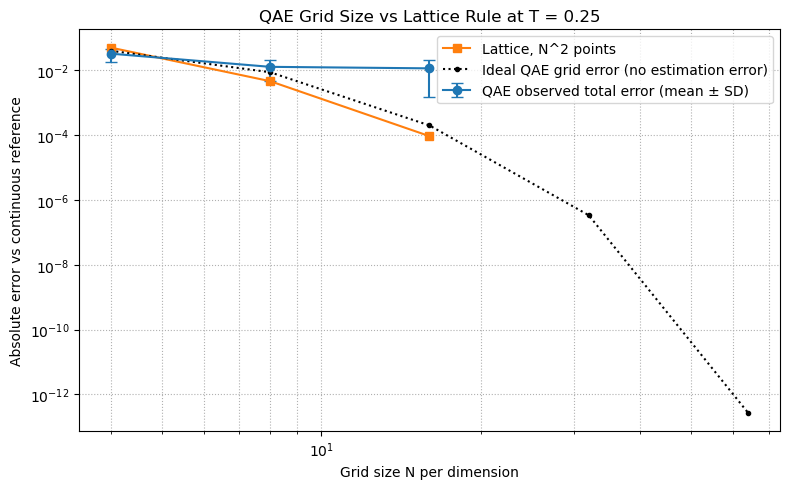

In [21]:
T_qae_study = 0.25
N_qae_study = [4, 8, 16]
epsilon_qae_study = 0.05
qae_repeats = 5
qae_lattice_results = []
ref_qae_study = reference_values[T_qae_study]

for N in N_qae_study:
    n_per_dim_study = int(np.log2(N))
    A_study = build_state_preparation(T_qae_study, n_per_dim_study)
    n_coord_study = A_study.num_qubits - 1
    problem_study = EstimationProblem(
        state_preparation=A_study,
        objective_qubits=[n_coord_study],
    )
    qae_errors = []
    oracle_queries = []
    for repetition in range(qae_repeats):
        sampler_study = StatevectorSampler(seed=42 + repetition)
        iae_study = IterativeAmplitudeEstimation(
            epsilon_target=epsilon_qae_study,
            alpha=0.05,
            sampler=sampler_study,
        )
        result = iae_study.estimate(problem_study)
        qae_errors.append(abs(result.estimation - ref_qae_study))
        oracle_queries.append(result.num_oracle_queries)

    lattice_estimate = lattice_rule_integral(T_qae_study, N * N)
    lattice_error = abs(lattice_estimate - ref_qae_study)
    qae_lattice_results.append({
        'N': N,
        'grid_points': N * N,
        'qubits': A_study.num_qubits,
        'qae_errors': qae_errors,
        'mean_qae_error': np.mean(qae_errors),
        'std_qae_error': np.std(qae_errors),
        'lattice_error': lattice_error,
        'mean_oracle_queries': np.mean(oracle_queries),
        'win_fraction': np.mean(np.array(qae_errors) < lattice_error),
    })

print(f'QAE eps target = {epsilon_qae_study:.3f}; errors are against the continuous reference ({qae_repeats} runs)')
print(f'{"N":>4} | {"N^2 points":>10} | {"qubits":>6} | {"QAE mean ± SD":>20} | {"lattice error":>14} | {"mean Grover queries":>19} | QAE win rate')
print('-' * 112)
for row in qae_lattice_results:
    print(f'{row["N"]:4d} | {row["grid_points"]:10d} | {row["qubits"]:6d} | {row["mean_qae_error"]:9.3e} ± {row["std_qae_error"]:8.2e} | {row["lattice_error"]:14.3e} | {row["mean_oracle_queries"]:19.1f} | {row["win_fraction"]:10.0%}')

qae_grid_scan = [4, 8, 16, 32, 64]
ideal_qae_grid_errors = [
    abs(uniform_grid_integral(T_qae_study, N) - ref_qae_study)
    for N in qae_grid_scan
]
matched_lattice_errors = [
    abs(lattice_rule_integral(T_qae_study, N * N) - ref_qae_study)
    for N in qae_grid_scan
]
stable_crossovers = [
    N for i, N in enumerate(qae_grid_scan)
    if all(ideal_qae_grid_errors[j] < matched_lattice_errors[j] for j in range(i, len(qae_grid_scan)))
]
print('\nIdeal grid-resolution comparison (before QAE estimation error):')
if stable_crossovers:
    print(f'From N={stable_crossovers[0]} onward in this scan, the N x N QAE grid error stays below the lattice-rule error at N^2 points.')
else:
    print('No stable crossover found in this grid-size scan.')

plt.figure(figsize=(8, 5))
plt.errorbar([r['N'] for r in qae_lattice_results], [r['mean_qae_error'] for r in qae_lattice_results], yerr=[r['std_qae_error'] for r in qae_lattice_results], fmt='o-', capsize=4, label='QAE observed total error (mean ± SD)')
plt.loglog([r['N'] for r in qae_lattice_results], [r['lattice_error'] for r in qae_lattice_results], 's-', label='Lattice, N^2 points')
plt.loglog(qae_grid_scan, ideal_qae_grid_errors, 'k:', marker='.', label='Ideal QAE grid error (no estimation error)')
plt.xlabel('Grid size N per dimension')
plt.ylabel('Absolute error vs continuous reference')
plt.title(f'QAE Grid Size vs Lattice Rule at T = {T_qae_study}')
plt.legend()
plt.grid(True, which='both', linestyle=':')
plt.tight_layout()
plt.show()